# Rainfall over time

The 22 rainfall totals below were transcribed from the supplied photograph. Values are in **millimetres (mm)**. Every year from **1929 to 2019** appears on the horizontal axis; years without a reported value remain blank. Missing values are **not zero**, and no values are interpolated.

The horizontal axis begins at **1929**, as requested. The handwritten heading mentions 1929 without giving a rainfall total for that year, and the first listed measurement is for 1963. The 2019 entry is marked **DROOG** (dry) in the photograph. No totals are inferred from the heading, and every listed measurement is included.

**Run:** Open this notebook in Jupyter or VS Code, select a Python 3 kernel, and run all cells. It requires `pandas` and `matplotlib`. If either is missing, run `%pip install pandas matplotlib` in a new cell first.

The data are embedded below, so the notebook does not need the original image or an external data file. Edit the table entries here if a transcription needs correcting.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Transcribed year, rainfall (mm), and any note beside the measurement.
records = [
    (1963, 562, ""),
    (1971, 573, ""),
    (1974, 714, ""),
    (1976, 730, ""),
    (1977, 499, ""),
    (1981, 587, ""),
    (1985, 489, ""),
    (1989, 516, ""),
    (1993, 478, ""),
    (1994, 477, ""),
    (1995, 551, ""),
    (1996, 541, ""),
    (2000, 564, ""),
    (2001, 570, ""),
    (2002, 424, ""),
    (2006, 459, ""),
    (2007, 452, ""),
    (2010, 450, ""),
    (2011, 570, ""),
    (2012, 531, ""),
    (2014, 479, ""),
    (2019, 240, "DROOG (dry)"),
]

rainfall = (
    pd.DataFrame(records, columns=["year", "rainfall_mm", "source_note"])
    .set_index("year", verify_integrity=True)
    .sort_index()
)
rainfall

C:\Users\Andre Nel\AppData\Local\Temp\ipykernel_28380\4058419007.py:32: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  .set_index("year", verify_integrity=True)


,rainfall_mm,source_note
year,,
1963,562,
1971,573,
1974,714,
1976,730,
1977,499,
1981,587,
1985,489,
1989,516,
1993,478,


## Preserve the gaps in time

Reindex to a complete sequence of years. Unreported years become `NaN` (missing), rather than zero. Bars use numeric year positions, and the tick labels include **every year**, so a long gap occupies proportionally more space.

The range begins in 1929 and ends at the last reported measurement. The years 1929–1962 have no reported values and remain blank.

In [ ]:
start_year = 1929
end_year = int(rainfall.index.max())
all_years = pd.Index(range(start_year, end_year + 1), name="year")

annual_rainfall = rainfall["rainfall_mm"].reindex(all_years)
print(
    f"{annual_rainfall.notna().sum()} reported years; "
    f"{annual_rainfall.isna().sum()} unreported years "
    f"between {start_year} and {end_year}."
)

22 reported years; 69 unreported years between 1929 and 2019.


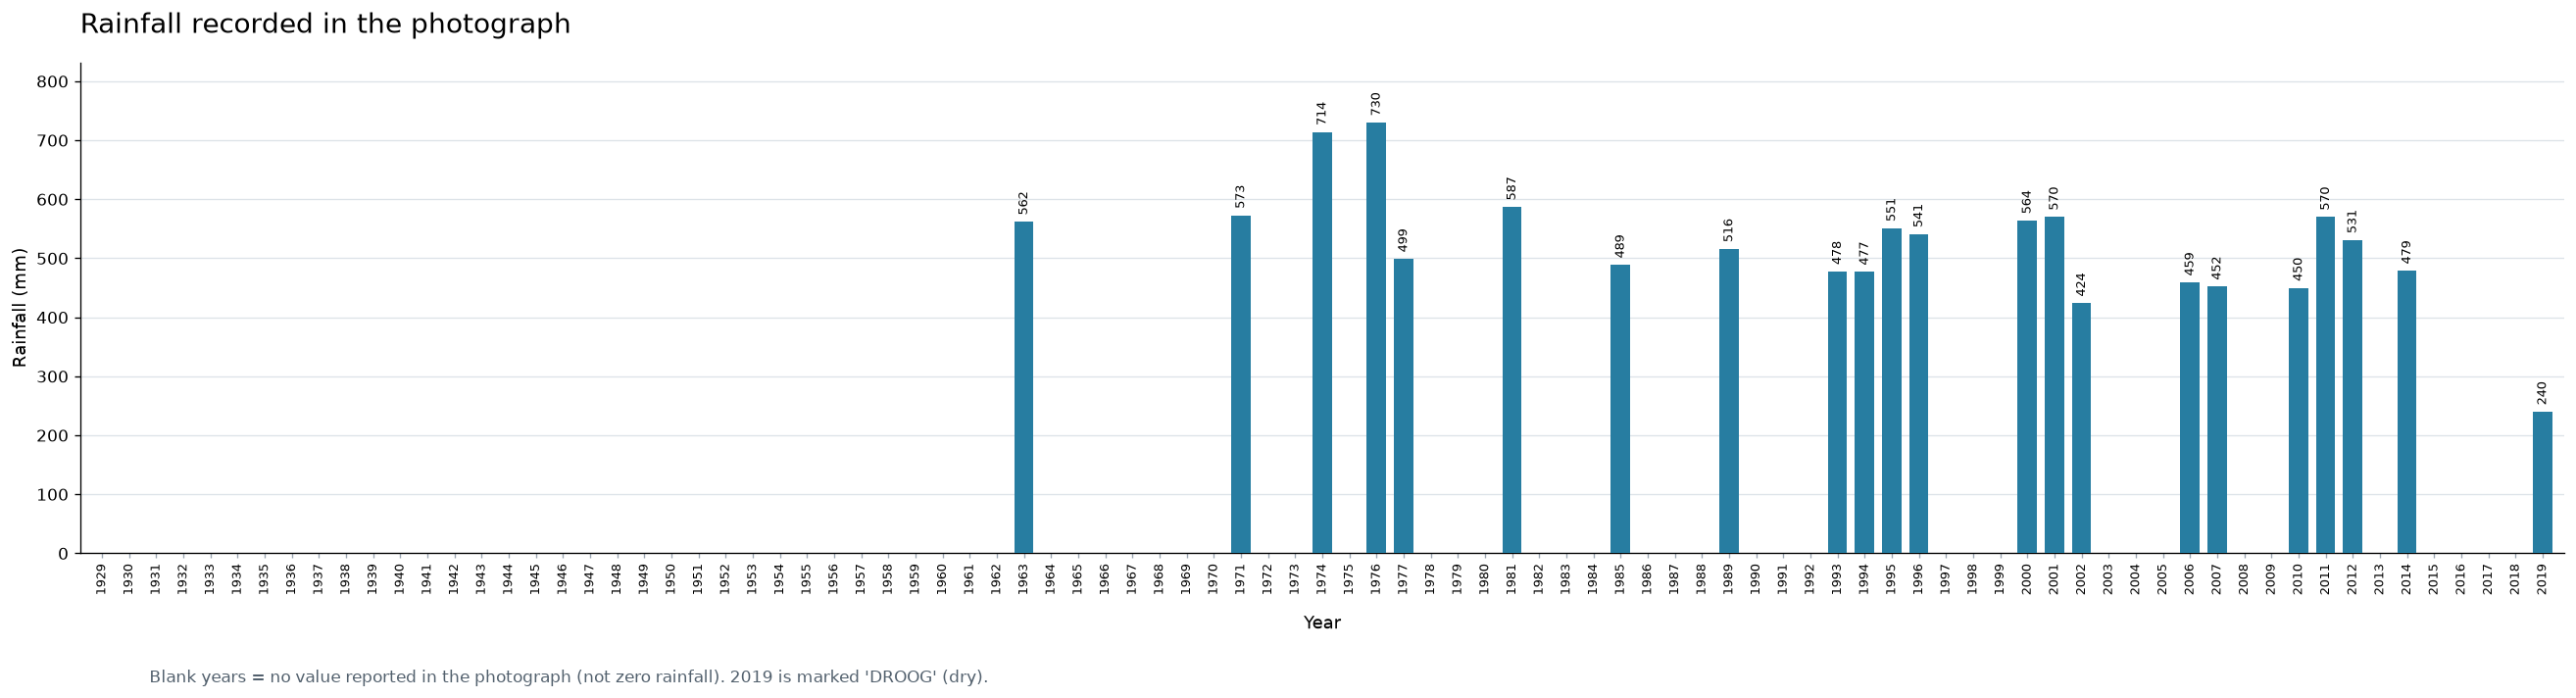

In [ ]:
# Only observed totals receive bars; all calendar years retain axis space.
reported = annual_rainfall.dropna()
fig, ax = plt.subplots(figsize=(22, 6), dpi=120)

bars = ax.bar(
    reported.index,
    reported.values,
    width=0.72,
    color="#277DA1",
    zorder=3,
)
ax.bar_label(bars, fmt="%.0f", padding=4, fontsize=8, rotation=90)

ax.set_title("Rainfall recorded in the photograph", loc="left", fontsize=17, pad=18)
ax.set_xlabel("Year", fontsize=11, labelpad=12)
ax.set_ylabel("Rainfall (mm)", fontsize=11)
ax.set_xticks(all_years)
ax.set_xticklabels(all_years, rotation=90, fontsize=8)
ax.set_xlim(start_year - 0.8, end_year + 0.8)
ax.set_ylim(0, reported.max() * 1.14)
ax.grid(axis="y", color="#DDE3E8", linewidth=0.8, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="x", length=3, color="#9AA5B1")

fig.text(
    0.06,
    0.025,
    "Blank years = no value reported in the photograph (not zero rainfall). "
    "2019 is marked 'DROOG' (dry).",
    fontsize=10,
    color="#52606D",
)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()